# C3 · Final views and visual system

**Course:** Business Intelligence · IIB423T-1 · Universidad del Desarrollo
**Group:** 01 · Alessandro Lavezzi · José Saavedra
**Reading order:** (1) `W2_project.ipynb` data preparation and split → (2) `C2_classification.ipynb` model, reference and evaluation → (3) **this notebook**: the three final views and the visual rules behind them.

This notebook does not train anything. It draws the results saved in `C2_classification.ipynb` (section 3.2 coefficients, section 4.1 test-set metrics and confusion matrices). The shared rules live in `../visual_system/style.py`; every chart below imports them. Figures are saved to `../figures/c3_*.png`.

## 1. Visual system: rules and where they are implemented

| Rule | Definition | Implemented in |
|---|---|---|
| Colour meaning | blue `#1F5FA8` = logistic regression; grey `#8C8C8C` = reference rule, neutral context and share ramp; amber `#D9822B` = highlight only (differences, errors, dominant factor) | `style.py` constants `C_MODEL`, `C_REF`, `C_ALERT` |
| Non-colour cues | reference rule hatched (`///`); every value printed on the mark; circle = numeric feature, diamond = category; error cells named in words | `HATCH_REF`; cells 3–5 below |
| Text | title = the finding (bold 14); subtitle = population, period and unit (9.5, grey); source line (8.5) | `heading()`, `source()` |
| Scales | scores 0–1 from zero (no truncation); shares 0–100% with the same scale in both panels; odds ratios on a log scale centred on 1 | cells 3–5 below |
| Highlighting | one highlight per view: amber differences (view 1), amber frame on the two error cells (view 2), amber dominant factor (view 3) | cells 3–5 below |
| Layout | title → subtitle → plot → legend → source; legends never cover data; reference before model, left to right | `heading()`; cells 3–5 below |

**Exceptions.** View 3 shows a different measure (odds ratio), so it has its own log scale instead of the 0–1 score scale. It keeps the colour meaning (blue = model result, amber = the one thing to notice).

**Design selection (from W3).** Each of the three views was drawn in an earlier, weaker version and redesigned. The selected design was kept because each view supports one task for one audience (people-management units deciding whom to review): *compare* model and rule (view 1), *summarize* the errors (view 2), *identify* the dominant factor (view 3).

In [1]:
import sys
sys.path.insert(0, "../visual_system")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from pathlib import Path
import style
from style import C_MODEL, C_REF, C_ALERT, C_INK, C_GRID, HATCH_REF, CONTEXT, heading, source
style.apply()
OUT = Path("../figures"); OUT.mkdir(exist_ok=True)

## 2. Data used by the views (copied from the saved C2 outputs)
Test set: 1,192 people, 204 persistent (17.1%). Positive class = persistent. Threshold 0.35 fixed on validation. The checks below confirm the numbers add up to the C2 results.

In [2]:
metrics = pd.DataFrame({                      # C2 section 4.1, test-set metrics
    "Reference rule":      {"Precision": 0.714, "Recall": 0.760, "F1": 0.736},
    "Logistic regression": {"Precision": 0.664, "Recall": 0.833, "F1": 0.739},
}).T
cm = {                                        # C2 section 4.1: [[TP, FN], [FP, TN]]
    "Reference rule": np.array([[155, 49], [62, 926]]),
    "Logistic regression (threshold 0.35)": np.array([[170, 34], [86, 902]]),
}
odds = pd.Series({                            # C2 section 3.2, odds ratios (training fit)
    "% of months with overtime (per SD)": 5.929, "Entitled to overtime (derecho_x)": 1.914,
    "Service: Norte": 1.368, "Service: Occidente": 1.324, "Service: SurOriente": 1.296,
    "Hours per month (per SD)": 1.183, "Staff: Directivo": 0.970, "Staff: Auxiliar": 0.980,
    "Staff: Médicos y afines": 0.821, "Months on payroll (per SD)": 0.789, "Service: Oriente": 0.736,
    "Staff: Técnico": 0.633, "Staff: Profesional": 0.626, "Service: Sur": 0.461})
numeric_feats = {"% of months with overtime (per SD)", "Entitled to overtime (derecho_x)",
                 "Hours per month (per SD)", "Months on payroll (per SD)"}

# consistency checks with C2
for name, m in cm.items():
    assert m.sum() == 1192 and m[0].sum() == 204
    tp, fn, fp, tn = m[0, 0], m[0, 1], m[1, 0], m[1, 1]
    prec, rec = tp / (tp + fp), tp / (tp + fn)
    key = "Logistic regression" if "Logistic" in name else "Reference rule"
    assert abs(prec - metrics.loc[key, "Precision"]) < 0.001 and abs(rec - metrics.loc[key, "Recall"]) < 0.001
print("Checks passed: matrices add to 1,192 people (204 persistent) and agree with the metrics table.")
print(metrics.round(3).to_string())

Checks passed: matrices add to 1,192 people (204 persistent) and agree with the metrics table.
                     Precision  Recall     F1
Reference rule           0.714   0.760  0.736
Logistic regression      0.664   0.833  0.739


## 3. View 1 · Compare the model with the reference rule (task: *compare*)

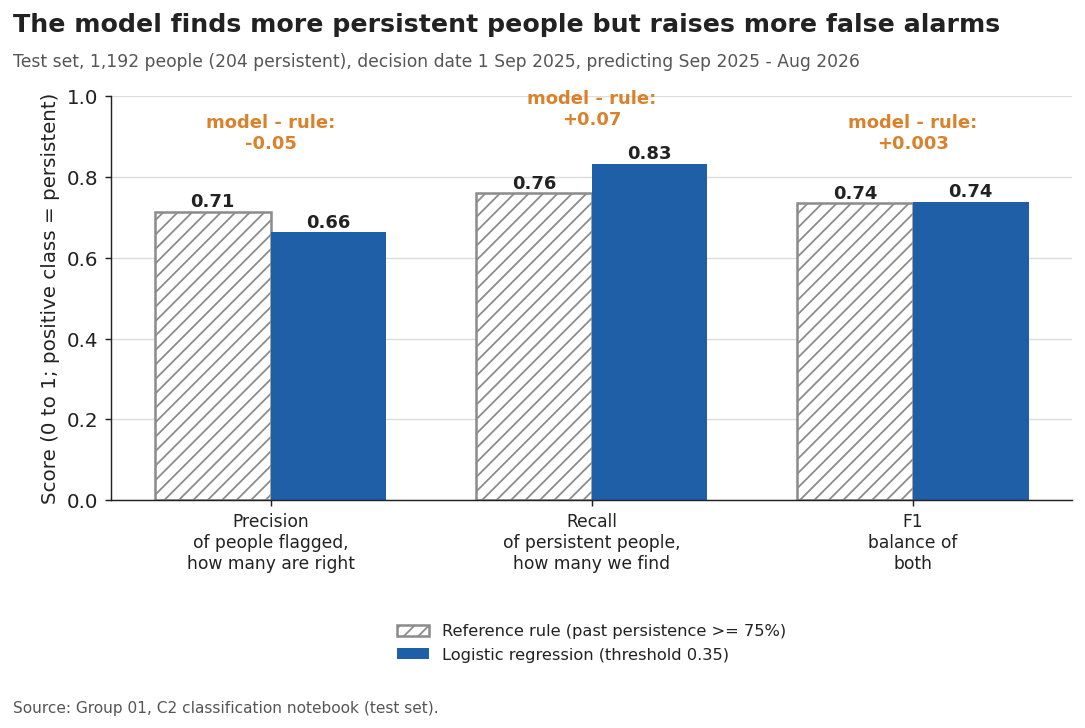

In [3]:
fig, ax = plt.subplots(figsize=(8.4, 5.6))
labels = ["Precision\nof people flagged,\nhow many are right", "Recall\nof persistent people,\nhow many we find", "F1\nbalance of\nboth"]
x = np.arange(3); w = 0.36
ref = metrics.loc["Reference rule"].values; mod = metrics.loc["Logistic regression"].values
b1 = ax.bar(x - w/2, ref, w, color="white", edgecolor=C_REF, hatch=HATCH_REF, linewidth=1.4, label="Reference rule (past persistence >= 75%)")
b2 = ax.bar(x + w/2, mod, w, color=C_MODEL, label="Logistic regression (threshold 0.35)")
for bars in (b1, b2):
    for r in bars:
        ax.text(r.get_x() + r.get_width()/2, r.get_height() + 0.012, f"{r.get_height():.2f}", ha="center", fontsize=10, fontweight="bold")
ax.set_ylim(0, 1); ax.set_yticks(np.arange(0, 1.01, 0.2)); ax.yaxis.grid(True, color=C_GRID); ax.set_axisbelow(True)
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9.5)
ax.set_ylabel("Score (0 to 1; positive class = persistent)")
for xi, txt, yy in [(0, "-0.05", 0.87), (1, "+0.07", 0.93), (2, "+0.003", 0.87)]:
    ax.text(xi, yy, f"model - rule:\n{txt}", ha="center", color=C_ALERT, fontweight="bold", fontsize=10)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.27), ncol=1, fontsize=9)
y0 = heading(fig, "The model finds more persistent people but raises more false alarms", CONTEXT)
fig.subplots_adjust(left=0.1, right=0.98, top=y0 - 0.02, bottom=0.30)
source(fig); fig.savefig(OUT / "c3_view1_model_vs_rule.png"); plt.show()

**Reading.** Recall rises from 0.76 to 0.83 and precision falls from 0.71 to 0.66; F1 is practically equal (0.739 vs 0.736). With about 200 persistent people in the test set this difference is within sampling variation, so we do not claim that the model predicts better than the rule (C2, section 5).

## 4. View 2 · Summarize the errors (task: *summarize*)

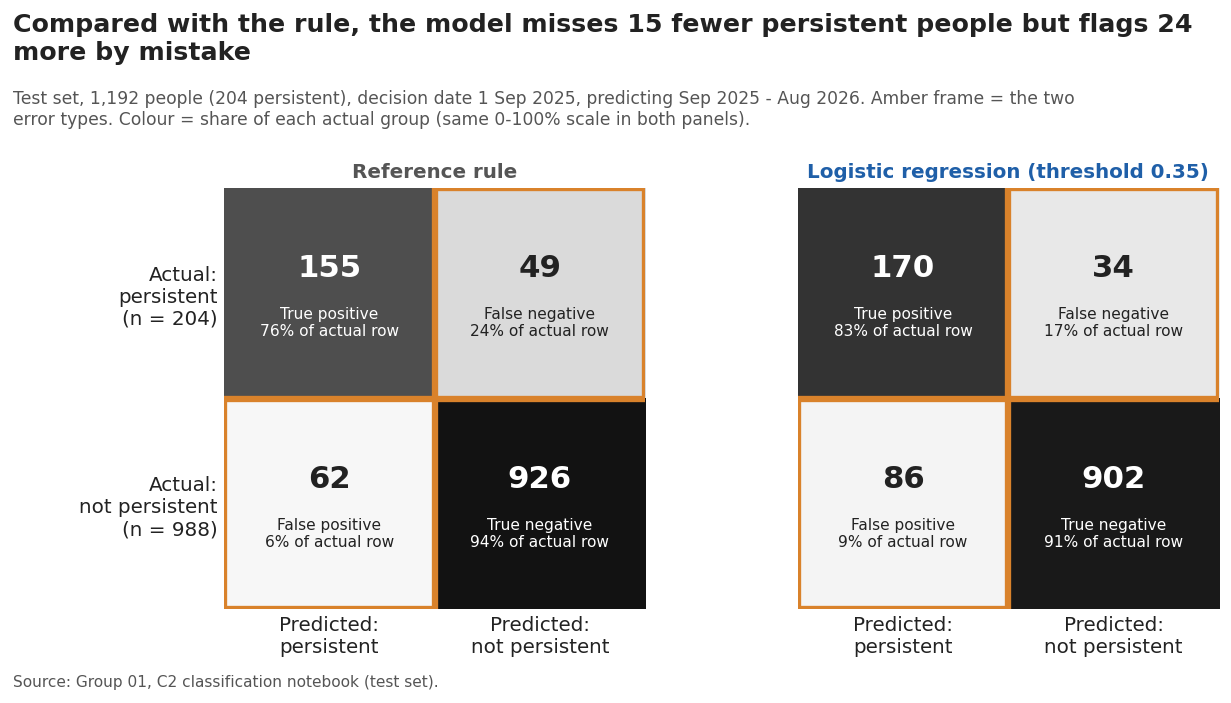

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5.4), sharey=True)
cell_names = [["True positive", "False negative"], ["False positive", "True negative"]]
for ax, name in zip(axes, ["Reference rule", "Logistic regression (threshold 0.35)"]):
    m = cm[name]; share = m / m.sum(axis=1, keepdims=True)           # share of each ACTUAL group, same 0-100% scale in both panels
    ax.imshow(share, cmap=plt.cm.Greys, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            col = "white" if share[i, j] > 0.55 else C_INK
            ax.text(j, i - 0.12, f"{m[i, j]:,}", ha="center", va="center", fontsize=17, fontweight="bold", color=col)
            ax.text(j, i + 0.14, f"{cell_names[i][j]}\n{share[i, j]*100:.0f}% of actual row", ha="center", va="center", fontsize=8.5, color=col)
    for (i, j) in [(0, 1), (1, 0)]:                                   # the two error types
        ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, fill=False, edgecolor=C_ALERT, linewidth=3.5))
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Predicted:\npersistent", "Predicted:\nnot persistent"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Actual:\npersistent\n(n = 204)", "Actual:\nnot persistent\n(n = 988)"])
    ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_title(name, fontsize=11, fontweight="bold", color=C_MODEL if "Logistic" in name else "#555555", pad=6)
y0 = heading(fig, "Compared with the rule, the model misses 15 fewer persistent people but flags 24 more by mistake",
             CONTEXT + ". Amber frame = the two error types. Colour = share of each actual group (same 0-100% scale in both panels).",
             width_title=80, width_sub=120)
fig.subplots_adjust(left=0.13, right=0.98, top=y0 - 0.06, bottom=0.12, wspace=0.08)
source(fig); fig.savefig(OUT / "c3_view2_errors.png"); plt.show()

**Reading.** False negatives fall from 49 to 34 and false positives rise from 62 to 86. A false positive means a position reviewed for staffing although its overtime would not have persisted; a false negative means another year of overtime without review (C2, section 4.2).

## 5. View 3 · Identify the dominant factor (task: *identify*)

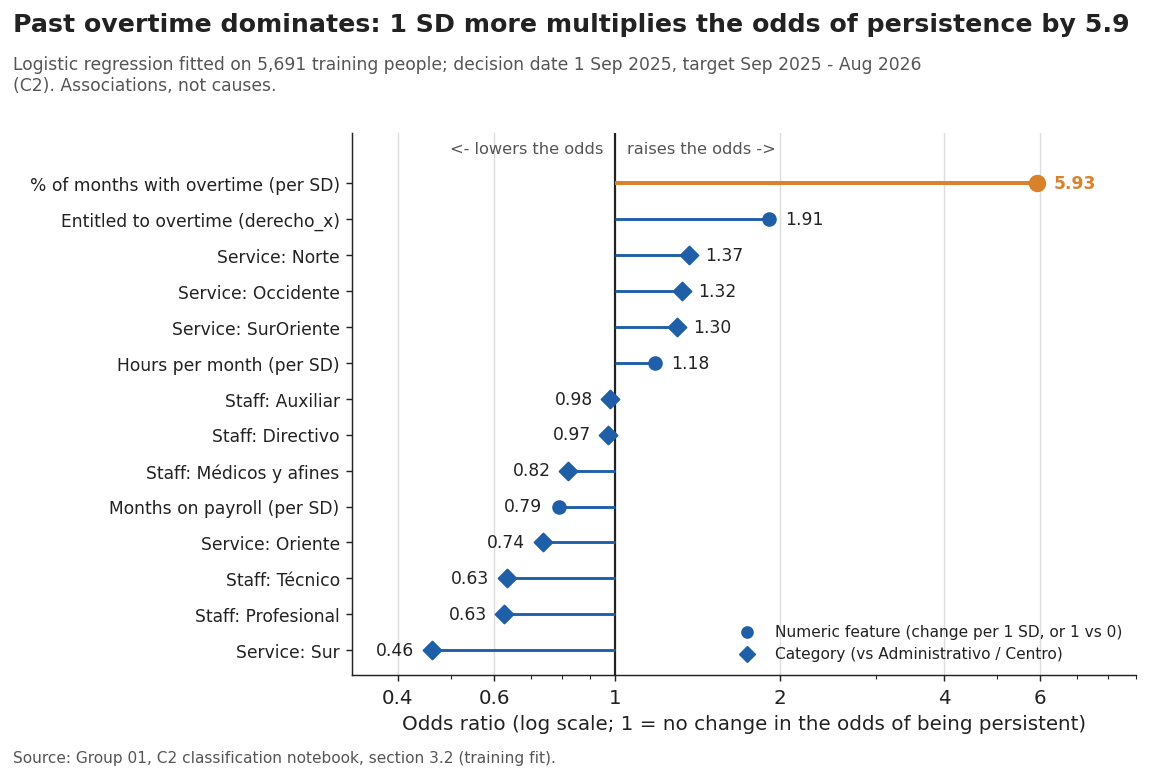

In [5]:
s = odds.sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(s)); ax.set_xscale("log"); ax.axvline(1, color=C_INK, linewidth=1.2)
for yi, (name, v) in zip(y, s.items()):
    top = name.startswith("% of months")
    color = C_ALERT if top else C_MODEL
    ax.hlines(yi, 1, v, color=color, linewidth=2.2 if top else 1.6)
    ax.scatter(v, yi, s=75 if top else 50, color=color, marker="o" if name in numeric_feats else "D", zorder=3)
    ax.text(v * (1.07 if v >= 1 else 0.93), yi, f"{v:.2f}", va="center", ha="left" if v >= 1 else "right",
            fontsize=9.5, fontweight="bold" if top else "normal", color=C_ALERT if top else C_INK)
ax.set_yticks(y); ax.set_yticklabels(s.index, fontsize=9.5)
ax.set_xticks([0.4, 0.6, 1, 2, 4, 6]); ax.set_xticklabels(["0.4", "0.6", "1", "2", "4", "6"]); ax.set_xlim(0.33, 9)
ax.xaxis.grid(True, color=C_GRID); ax.set_axisbelow(True)
ax.set_xlabel("Odds ratio (log scale; 1 = no change in the odds of being persistent)")
ax.set_ylim(-0.7, len(s) + 0.4)
ax.text(0.95, len(s) - 0.15, "<- lowers the odds", fontsize=9, color="#555555", ha="right")
ax.text(1.05, len(s) - 0.15, "raises the odds ->", fontsize=9, color="#555555", ha="left")
ax.scatter([], [], marker="o", color=C_MODEL, label="Numeric feature (change per 1 SD, or 1 vs 0)")
ax.scatter([], [], marker="D", color=C_MODEL, label="Category (vs Administrativo / Centro)")
ax.legend(frameon=False, loc="lower right", fontsize=8.5)
y0 = heading(fig, "Past overtime dominates: 1 SD more multiplies the odds of persistence by 5.9",
             "Logistic regression fitted on 5,691 training people; decision date 1 Sep 2025, target Sep 2025 - Aug 2026 (C2). Associations, not causes.", width_title=90)
fig.subplots_adjust(left=0.30, right=0.97, top=y0 - 0.02, bottom=0.12)
source(fig, "Source: Group 01, C2 classification notebook, section 3.2 (training fit).")
fig.savefig(OUT / "c3_view3_factors.png"); plt.show()

**Reading.** The share of past months with overtime is by far the strongest signal (odds ratio 5.93 per standard deviation); that is why the one-variable reference rule is already strong. The other factors are associations, not causes.

## 6. Limits of these views
- **View 1** hides the uncertainty of the metrics (about 200 persistent people); confidence intervals would need person-level predictions.
- **View 2** shows shares per actual group, which can make false positives (9%) look small although they are 86 people in total (24 more than the 62 of the rule).
- **View 3** mixes per-standard-deviation effects and category-vs-reference effects; shapes flag this but do not make them directly comparable.